In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.patches as mpatches

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, cross_val_predict, permutation_test_score
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,roc_auc_score, RocCurveDisplay)

from scipy.stats import wilcoxon

In [3]:
freqTable = pd.read_csv(r"C:\Users\barth\Downloads\table.tsv", sep="\t", skiprows=1) #frequency table import
freqTable = freqTable.rename(columns = {"#OTU ID" : "FeatureID"})
freqTable.head()

,FeatureID,SRR15018640,SRR15018641,SRR15018642,SRR15018643,SRR15018644,SRR15018645,SRR15018646,SRR15018647,SRR15018648,...,SRR15018731,SRR15018732,SRR15018733,SRR15018734,SRR15018735,SRR15018736,SRR15018737,SRR15018738,SRR15018739,SRR15018740
0,47f27fc06a83dc52f45c8377103c1540,634.0,378.0,1394.0,1282.0,1526.0,1529.0,1237.0,1005.0,698.0,...,1935.0,1056.0,1098.0,2482.0,3241.0,925.0,154.0,288.0,1227.0,2898.0
1,6801b02d1ef62a4cd2ab73f4f39c0bcf,483.0,323.0,1141.0,982.0,1220.0,1123.0,930.0,719.0,490.0,...,1479.0,897.0,970.0,2086.0,2626.0,785.0,95.0,213.0,1063.0,2577.0
2,f204981ee8c56f364d1ff252708c0acc,540.0,354.0,1192.0,1009.0,1152.0,1141.0,890.0,726.0,545.0,...,1510.0,856.0,923.0,2120.0,2570.0,821.0,122.0,194.0,1019.0,2466.0
3,a3cf5ec67c5c5b9d53367f9262e0f05e,516.0,276.0,1130.0,1034.0,1264.0,1251.0,1018.0,779.0,550.0,...,1450.0,888.0,879.0,2026.0,2559.0,819.0,127.0,236.0,970.0,2388.0
4,d4306a4038812836c0f74289076a05ab,358.0,170.0,1029.0,947.0,820.0,717.0,928.0,940.0,527.0,...,1261.0,649.0,607.0,1923.0,3440.0,751.0,0.0,0.0,851.0,2457.0


In [4]:
tax = pd.read_csv(r"C:\Users\barth\Downloads\taxonomy.tsv", sep = "\t", skiprows=1, header=None) #taxonomy table import
tax.columns = ['FeatureID', 'Taxon', 'Confidence']

#Pulling genus and other
unwanted = ["Unassigned", "Mitochondria", "Eukaryota", "uncultured"]

tax["Genus"] = tax["Taxon"].str.extract(r"g__([^;]+)")
tax["Genus"] = tax["Genus"].fillna("Unassigned") #Fills empty with something
merged = freqTable.merge(tax[["FeatureID", "Taxon", "Genus"]], on="FeatureID")

#print(merged[merged.columns[1:102]].sum().sum())

mask = merged["Taxon"].str.contains("|".join(unwanted), case=False, na=False)
filtered = merged[~mask]

genusTable = filtered.groupby("Genus").sum(numeric_only=True)

#print(genusTable.sum().sum())
#print(genusTable.shape)

removed = merged[mask]
#print(removed[removed.columns[1:102]].sum().sum())
#print(removed)

In [5]:
#Filtering next steps?
totalCounts = genusTable.sum(axis=1)
prevalence = (genusTable > 0).sum(axis=1)
genusTableFiltered = genusTable[(prevalence >= 3) & (totalCounts >= 20)]
#genusTableFiltered = genusTable[(prevalence >= 3)]
print(genusTableFiltered.shape)

(134, 101)


## CLR, PCR, and t-SNE ##

In [6]:
# Add pseudocount
data = genusTableFiltered + 1

# Geometric mean per sample
geomMean = np.exp(np.log(data).mean(axis=0))

# CLR transform
clrTable = np.log(data / geomMean)
data.head()

,SRR15018640,SRR15018641,SRR15018642,SRR15018643,SRR15018644,SRR15018645,SRR15018646,SRR15018647,SRR15018648,SRR15018649,...,SRR15018731,SRR15018732,SRR15018733,SRR15018734,SRR15018735,SRR15018736,SRR15018737,SRR15018738,SRR15018739,SRR15018740
Genus,,,,,,,,,,,,,,,,,,,,,
Actinomyces,1.0,1.0,1.0,1.0,1.0,1.0,28.0,143.0,12.0,1.0,...,21.0,39.0,43.0,82.0,1.0,70.0,1.0,1.0,1.0,140.0
Aeromonas,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,114.0,267.0,...,334.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,194.0,15.0
Agathobacter,1.0,1.0,1.0,1.0,1.0,1.0,1.0,36.0,1.0,1.0,...,1.0,1.0,1.0,84.0,1.0,1.0,1.0,44.0,1.0,21.0
Akkermansia,589.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1725.0,470.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
Alistipes,291.0,1.0,1.0,1.0,88.0,1.0,1.0,1.0,355.0,121.0,...,56.0,1.0,1.0,19.0,1.0,223.0,59.0,1.0,66.0,1.0


In [7]:
meta = pd.read_csv(r"C:\Users\barth\Downloads\crc_metadata.tsv", sep="\t")
meta = meta.set_index("sample-id")
merged_df = clrTable.T.join(meta, how="inner")

#Binning age into groups
merged_df["AgeGroup"] = pd.cut(
    merged_df["AGE"],
    bins=[0, 40, 60, 80, 100],
    labels=["<40", "40–60", "60–80", "80+"]
)

#Creating recurrence
merged_df["recurrence"] = merged_df["tissue"].apply(
    lambda x: "recurrent" if "recurrent CRC" in x and "non-recurrent" not in x else "non-recurrent"
)

#Creating tissue type column
merged_df["tissue_type"] = merged_df["tissue"].apply(
    lambda x: "CRC tumor" if "tumor" in x else "CRC normal"
)

group_col = "AgeGroup"
meta["AgeGroup"] = merged_df["AgeGroup"]
meta["recurrence"] = merged_df["recurrence"]
meta["tissue_type"] = merged_df["tissue_type"]

# Prepare data for PCA
taxa_cols = clrTable.T.columns.tolist()
meta_cols = meta.columns.tolist()


X = merged_df[taxa_cols].values
meta = merged_df[meta_cols]

n_components = min(10, X.shape[1])  # compute up to 10 PCs
pca = PCA(n_components=n_components)
pca_coords = pca.fit_transform(X)

explained = pca.explained_variance_ratio_ * 100
print(f"\nVariance explained — PC1: {explained[0]:.1f}%  PC2: {explained[1]:.1f}%")


Variance explained — PC1: 11.7%  PC2: 8.4%


In [8]:


clrTable = clrTable.T

# clrTable is samples x genera here
tt_df = clrTable.join(meta[["tissue_type", "Sample Name"]], how="inner")
tt_df["patient"] = tt_df["Sample Name"].str.split("-").str[0]

X_tt = tt_df[clrTable.columns].values
y_tt = (tt_df["tissue_type"] == "CRC tumor").astype(int).values   # 1 = tumor, 0 = normal
groups_tt = tt_df["patient"].values

print(f"Samples: {len(tt_df)} | Patients: {tt_df['patient'].nunique()}")
print(tt_df["tissue_type"].value_counts())

Samples: 101 | Patients: 51
tissue_type
CRC normal    51
CRC tumor     50
Name: count, dtype: int64


              precision    recall  f1-score   support

      normal       0.68      0.75      0.71        51
       tumor       0.71      0.64      0.67        50

    accuracy                           0.69       101
   macro avg       0.69      0.69      0.69       101
weighted avg       0.69      0.69      0.69       101

ROC AUC: 0.750


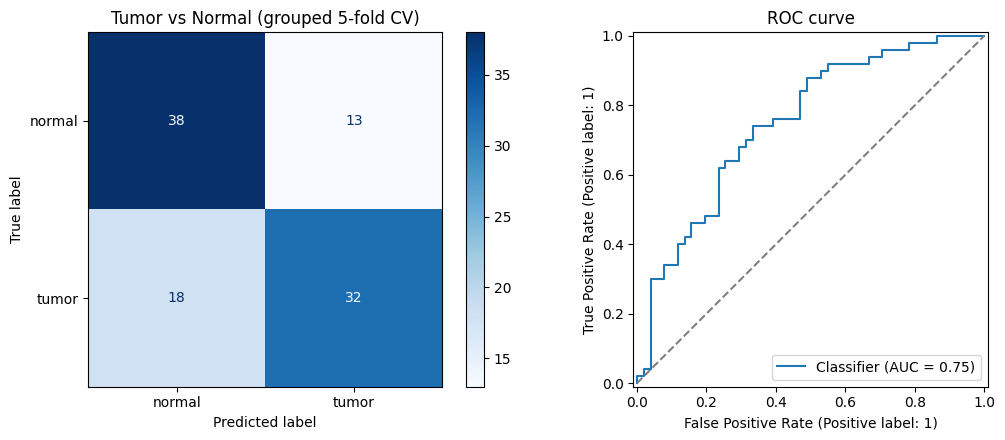

In [9]:
rf_tt = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

# Both samples from a patient always stay in the same fold
cv_tt = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Every sample gets predicted once, by a model that never saw that patient
proba_tt = cross_val_predict(rf_tt, X_tt, y_tt, groups=groups_tt,
                             cv=cv_tt, method="predict_proba")[:, 1]
pred_tt = (proba_tt >= 0.5).astype(int)

print(classification_report(y_tt, pred_tt, target_names=["normal", "tumor"]))
print(f"ROC AUC: {roc_auc_score(y_tt, proba_tt):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_tt, pred_tt, display_labels=["normal", "tumor"],
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Tumor vs Normal (grouped 5-fold CV)")
RocCurveDisplay.from_predictions(y_tt, proba_tt, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("ROC curve")
plt.tight_layout()
plt.show()

Observed AUC: 0.765 | Null mean: 0.500 | p = 0.0050


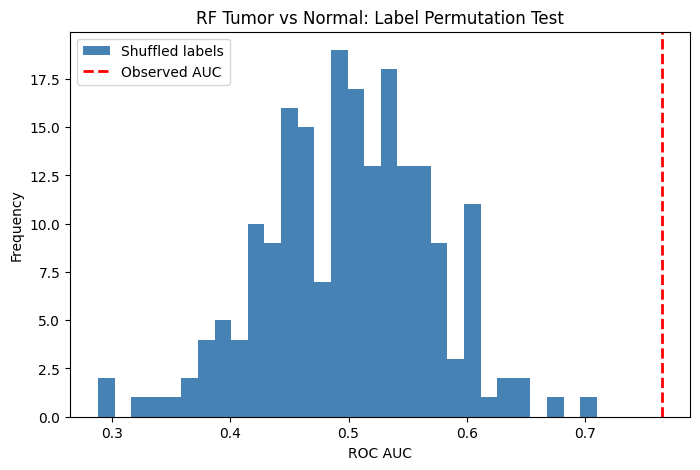

In [9]:
# Shuffles tumor/normal labels *within* each patient (swaps the pair),
# refits, and rescores. p-value = how often chance matches the real score.
score_tt, perm_scores_tt, p_tt = permutation_test_score(
    rf_tt, X_tt, y_tt, groups=groups_tt, cv=cv_tt,
    scoring="roc_auc", n_permutations=200, random_state=42,
)
print(f"Observed AUC: {score_tt:.3f} | Null mean: {perm_scores_tt.mean():.3f} | p = {p_tt:.4f}")

plt.figure(figsize=(8, 5))
plt.hist(perm_scores_tt, bins=30, color="steelblue", label="Shuffled labels")
plt.axvline(score_tt, color="red", linestyle="--", linewidth=2, label="Observed AUC")
plt.xlabel("ROC AUC")
plt.ylabel("Frequency")
plt.legend()
plt.title("RF Tumor vs Normal: Label Permutation Test")
plt.show()

Paired patients: 50 | Rows for model: 100
Row-level ROC AUC:    0.908
Pair-level accuracy:  0.840  (42/50 patients, chance = 0.5)


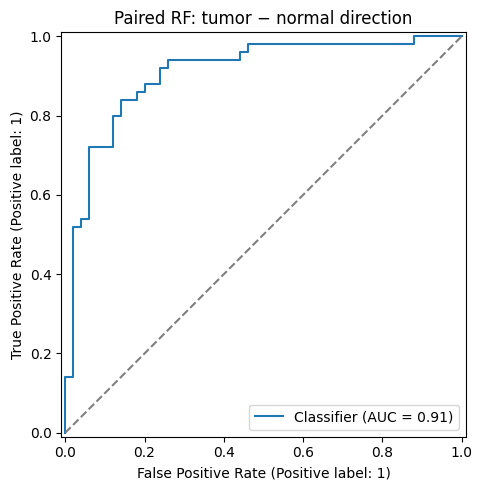

In [10]:


pair_df = clrTable.join(meta[["Sample Name"]], how="inner")
pair_df["patient"] = pair_df["Sample Name"].str.split("-").str[0]
pair_df["type"] = pair_df["Sample Name"].str.split("-").str[-1]   # TT or TN

tumor_p  = pair_df[pair_df["type"] == "TT"].set_index("patient")[clrTable.columns]
normal_p = pair_df[pair_df["type"] == "TN"].set_index("patient")[clrTable.columns]

# Keep patients that have both samples
shared_p = tumor_p.index.intersection(normal_p.index)
tumor_p  = tumor_p.loc[shared_p].astype(float)
normal_p = normal_p.loc[shared_p].astype(float)

delta_p = tumor_p - normal_p          # one row per patient: tumor minus normal (CLR)

# Two rows per patient: +delta = "tumor direction" (1), -delta = "normal direction" (0)
X_pair = np.vstack([delta_p.values, -delta_p.values])
y_pair = np.r_[np.ones(len(delta_p), int), np.zeros(len(delta_p), int)]
groups_pair = np.r_[shared_p.values, shared_p.values]

print(f"Paired patients: {len(shared_p)} | Rows for model: {len(X_pair)}")

rf_pair = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
)

cv_pair = GroupKFold(n_splits=5)   # a patient's +delta and -delta stay together

proba_pair = cross_val_predict(rf_pair, X_pair, y_pair, groups=groups_pair,
                               cv=cv_pair, method="predict_proba")[:, 1]

n_p = len(delta_p)
# Pair-level call - did the model score the true tumor-minus-normal direction higher?
pair_correct = proba_pair[:n_p] > proba_pair[n_p:]

print(f"Row-level ROC AUC:    {roc_auc_score(y_pair, proba_pair):.3f}")
print(f"Pair-level accuracy:  {pair_correct.mean():.3f}  "
      f"({pair_correct.sum()}/{n_p} patients, chance = 0.5)")

fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_predictions(y_pair, proba_pair, ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_title("Paired RF: tumor − normal direction")
plt.tight_layout()
plt.show()

Observed AUC: 0.906 | Null mean: 0.503 | p = 0.0050


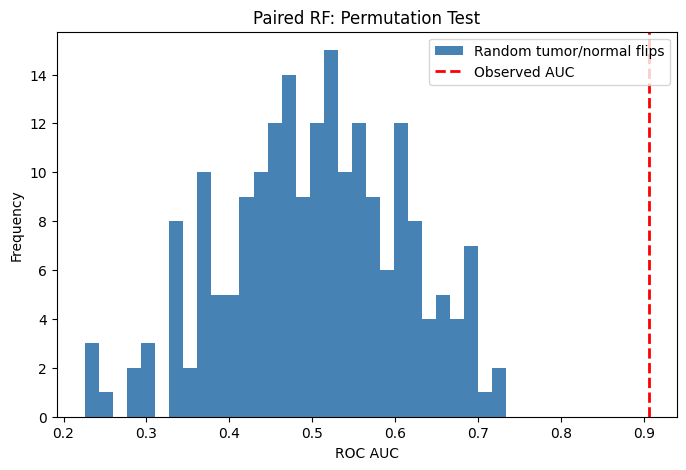

In [11]:
# With groups set, labels are shuffled only within each patient,
# which is the same as randomly flipping which sample is called "tumor"
score_pair, perm_pair, p_pair = permutation_test_score(
    rf_pair, X_pair, y_pair, groups=groups_pair, cv=cv_pair,
    scoring="roc_auc", n_permutations=200, random_state=42,
)
print(f"Observed AUC: {score_pair:.3f} | Null mean: {perm_pair.mean():.3f} | p = {p_pair:.4f}")

plt.figure(figsize=(8, 5))
plt.hist(perm_pair, bins=30, color="steelblue", label="Random tumor/normal flips")
plt.axvline(score_pair, color="red", linestyle="--", linewidth=2, label="Observed AUC")
plt.xlabel("ROC AUC")
plt.ylabel("Frequency")
plt.legend()
plt.title("Paired RF: Permutation Test")
plt.show()

                     importance  median_delta  wilcoxon_p
Selenomonas              0.0889        0.9226      0.0000
Faecalibacterium         0.0664       -1.4312      0.0000
Blautia                  0.0634       -1.4936      0.0000
Campylobacter            0.0549        1.0282      0.0000
Parabacteroides          0.0472       -1.5694      0.0000
Dorea                    0.0441       -1.3733      0.0000
Collinsella              0.0437       -0.8762      0.0000
Leptotrichia             0.0408        0.3517      0.0000
Aeromonas                0.0282        0.3777      0.0000
Treponema                0.0223        0.4223      0.0000
Alistipes                0.0211       -0.9060      0.0000
Coprococcus              0.0199       -0.6348      0.0004
Tannerella               0.0167        0.2361      0.0001
Family_XIII_UCG-001      0.0164        0.3171      0.0006
UCG-005                  0.0133       -0.0501      0.0157
Porphyromonas            0.0129        0.2292      0.0109
Terrisporobact

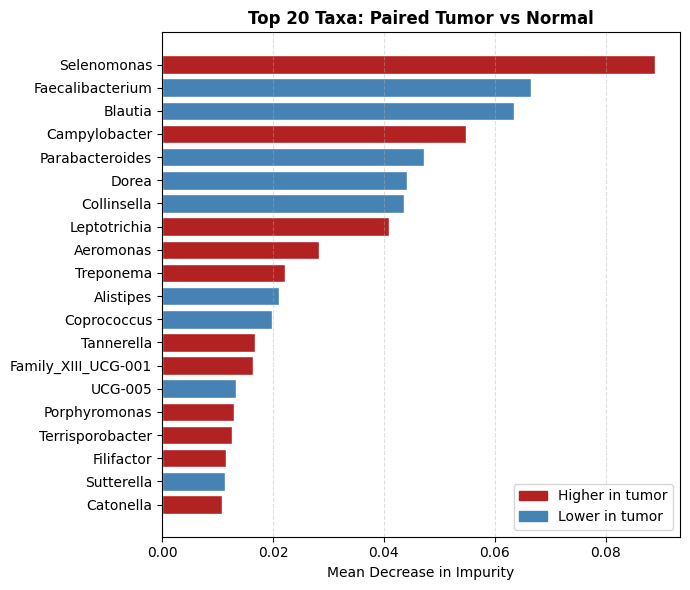

In [12]:
rf_pair.fit(X_pair, y_pair)
imp_pair = pd.Series(rf_pair.feature_importances_, index=clrTable.columns)
top20_pair = imp_pair.nlargest(20)

# For each top taxon: median shift and Wilcoxon signed-rank p-value
summary_pair = pd.DataFrame({
    "importance": top20_pair,
    "median_delta": delta_p[top20_pair.index].median(),
    "wilcoxon_p": [wilcoxon(delta_p[g], zero_method="zsplit").pvalue for g in top20_pair.index],
})
print(summary_pair.round(4))

plot_df = summary_pair.sort_values("importance")
colors = ["firebrick" if d > 0 else "steelblue" for d in plot_df["median_delta"]]

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(plot_df.index, plot_df["importance"], color=colors, edgecolor="white")
ax.set_xlabel("Mean Decrease in Impurity")
ax.set_title("Top 20 Taxa: Paired Tumor vs Normal", fontweight="bold")
ax.legend(handles=[mpatches.Patch(color="firebrick", label="Higher in tumor"),
                   mpatches.Patch(color="steelblue", label="Lower in tumor")])
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

PC1: 21.3%  PC2: 6.9%


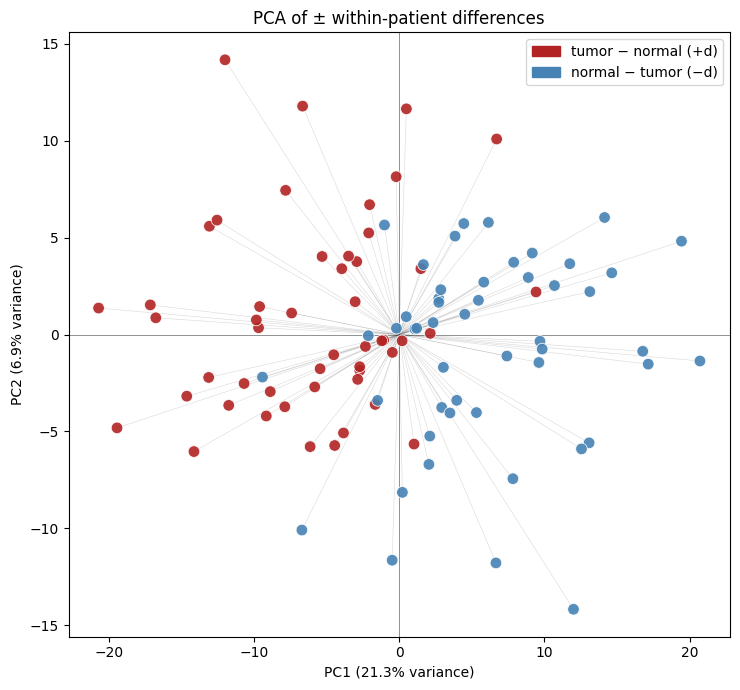

In [11]:
from sklearn.decomposition import PCA

pca_pair = PCA(n_components=10)
coords_pair = pca_pair.fit_transform(X_pair)
exp_pair = pca_pair.explained_variance_ratio_ * 100
print(f"PC1: {exp_pair[0]:.1f}%  PC2: {exp_pair[1]:.1f}%")

label_colors = np.where(y_pair == 1, "firebrick", "steelblue")

fig, ax = plt.subplots(figsize=(7.5, 7))
# Faint line joining each patient's +delta to its -delta twin
for i in range(n_p):
    ax.plot([coords_pair[i, 0], coords_pair[i + n_p, 0]],
            [coords_pair[i, 1], coords_pair[i + n_p, 1]],
            color="gray", lw=0.4, alpha=0.3, zorder=1)

ax.scatter(coords_pair[:, 0], coords_pair[:, 1], c=label_colors,
           s=70, edgecolors="white", linewidths=0.6, alpha=0.9, zorder=3)
ax.axhline(0, color="black", lw=0.6, alpha=0.5)
ax.axvline(0, color="black", lw=0.6, alpha=0.5)
ax.set_xlabel(f"PC1 ({exp_pair[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({exp_pair[1]:.1f}% variance)")
ax.set_title("PCA of ± within-patient differences")
ax.legend(handles=[mpatches.Patch(color="firebrick", label="tumor − normal (+d)"),
                   mpatches.Patch(color="steelblue", label="normal − tumor (−d)")])
plt.tight_layout()
plt.show()

t-SNE KL divergence: 0.4851


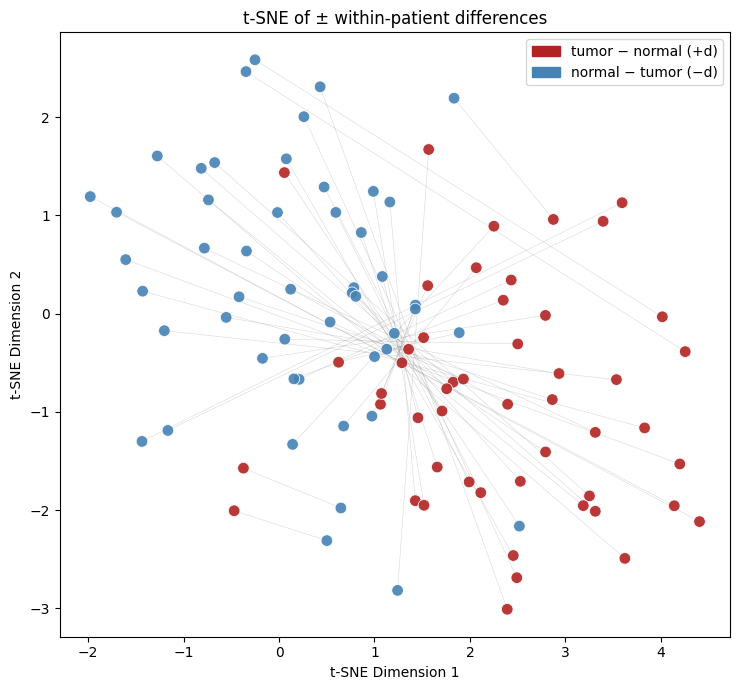

In [12]:
from sklearn.manifold import TSNE

tsne_pair = TSNE(
    n_components=2,
    perplexity=30,
    max_iter=1000,
    learning_rate="auto",
    init="pca",
    random_state=42,
)
tsne_pair_coords = tsne_pair.fit_transform(X_pair)
print(f"t-SNE KL divergence: {tsne_pair.kl_divergence_:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 7))
for i in range(n_p):
    ax.plot([tsne_pair_coords[i, 0], tsne_pair_coords[i + n_p, 0]],
            [tsne_pair_coords[i, 1], tsne_pair_coords[i + n_p, 1]],
            color="gray", lw=0.4, alpha=0.3, zorder=1)

ax.scatter(tsne_pair_coords[:, 0], tsne_pair_coords[:, 1], c=label_colors,
           s=70, edgecolors="white", linewidths=0.6, alpha=0.9, zorder=3)
ax.set_xlabel("t-SNE Dimension 1")
ax.set_ylabel("t-SNE Dimension 2")
ax.set_title("t-SNE of ± within-patient differences")
ax.legend(handles=[mpatches.Patch(color="firebrick", label="tumor − normal (+d)"),
                   mpatches.Patch(color="steelblue", label="normal − tumor (−d)")])
plt.tight_layout()
plt.show()